# Manila Rooftop Solar Potential: Full EDA Pipeline

**Goal:** assess whether rooftop solar can reduce Manila's reliance on fossil fuel, imported (Middle East) energy and Meralco grid supply.

**Pipeline**
1. Setup & configuration (all assumptions in one place)
2. Load & describe
3. Data quality audit
4. Cleaning (every step logged)
5. Univariate / bivariate EDA
6. Performance metrics (technical, concentration, national/Meralco context, scenarios)
7. Findings & limitations

> Units are **assumed** (the dataset has no documentation): area in m², capacity in kWp, energy in kWh/yr, `Estimated_capacity_factor` is actually specific yield in kWh/kWp/yr.
> Context numbers in section 1 (national generation, Meralco sales, tariff, emission factor) are **editable placeholders from memory, not verified**. Replace them with DOE / Meralco / ERC figures.

## 1. Setup & configuration

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

DATA = Path("manila_rooftop_solar_potential.csv")

# ---- Context assumptions: EDIT / VERIFY ----
NATIONAL_GEN_TWH   = 120.0   # Philippine annual generation (approx, unverified)
COAL_SHARE         = 0.62    # coal share of generation, 2024 (IEA/Ember via news)
OIL_SHARE_POWER    = 0.01    # oil share of power generation (DOE 2024 via news)
MERALCO_SALES_TWH  = 50.0    # Meralco annual energy sales (approx, unverified)
TARIFF_PHP_KWH     = 12.0    # blended residential-ish rate, PHP/kWh (illustrative)
GRID_EF_KG_KWH     = 0.70    # grid emission factor kgCO2/kWh (approx, unverified)
SELF_CONSUMPTION   = 0.80    # share of solar output used on-site (no storage)
PERFORMANCE_RATIO_HAIRCUT = 1.0  # multiply modelled energy for derating sensitivity
ADOPTION_SCENARIOS = [0.05, 0.10, 0.25, 0.50]   # share of buildings (by capacity) that install

## 2. Load & describe

In [2]:
raw = pd.read_csv(DATA, encoding="utf-8-sig")
print(raw.shape)
raw.head()

(301381, 12)


,uuid,City,Surface_area,Potential_installable_area,Peak_installable_capacity,Energy_potential_per_year,Assumed_building_type,Estimated_tilt,Estimated_building_height,Estimated_capacity_factor,Unit_installation_price,Comment
0,189a613a-98d3-4f79-bfbb-492bbd4485aa,Manila,152.98,88.39,17.16,"21,655.46",single family residential,11.76,7.89,"1,261.69",NaN,NaN
1,b5eef6a1-6000-46b5-b45c-b04e03d5002a,Manila,274.79,203.34,39.45,"43,590.32",multi-family residential,21.00,10.86,"1,105.00",NaN,NaN
2,c849379b-cda7-49d7-bc0a-6ab7ef0c688a,Manila,249.21,185.17,35.92,"46,233.22",multi-family residential,14.00,0.00,"1,287.00",NaN,NaN
3,65dd5848-c999-401c-9ff1-93086f46019f,Manila,138.31,83.57,16.21,"19,278.20",multi-family residential,15.83,8.47,"1,189.03",NaN,NaN
4,f1de2652-b6cc-4921-8a75-58cf262da95a,Manila,147.02,92.29,17.91,"23,187.11",multi-family residential,14.00,0.27,"1,295.00",NaN,NaN


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 301381 entries, 0 to 301380
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   uuid                        301381 non-null  str    
 1   City                        301381 non-null  str    
 2   Surface_area                301381 non-null  float64
 3   Potential_installable_area  301381 non-null  float64
 4   Peak_installable_capacity   301381 non-null  float64
 5   Energy_potential_per_year   301381 non-null  float64
 6   Assumed_building_type       301381 non-null  str    
 7   Estimated_tilt              301381 non-null  float64
 8   Estimated_building_height   299956 non-null  float64
 9   Estimated_capacity_factor   295984 non-null  float64
 10  Unit_installation_price     0 non-null       float64
 11  Comment                     0 non-null       float64
dtypes: float64(9), str(3)
memory usage: 27.6 MB


In [4]:
num_cols = raw.select_dtypes("number").columns.tolist()
cat_cols = raw.select_dtypes(exclude="number").columns.drop("uuid").tolist()
display(raw[num_cols].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99,.999]).T)
for c in cat_cols:
    print(f"\n{c}"); print(raw[c].value_counts(dropna=False))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
Surface_area,"301,381.00",137.38,297.09,0.00,7.16,14.36,40.13,78.98,150.16,413.36,979.34,"3,107.48","40,507.35"
Potential_installable_area,"301,381.00",88.69,233.98,0.00,0.00,4.80,19.25,43.13,89.46,298.43,733.68,"2,445.20","33,201.46"
Peak_installable_capacity,"301,381.00",17.21,45.40,0.00,0.00,0.93,3.73,8.37,17.36,57.90,142.33,474.37,"6,453.97"
Energy_potential_per_year,"301,381.00","21,275.54","57,490.26",0.00,0.00,"1,151.16","4,585.39","10,256.62","21,244.91","71,356.45","178,452.98","601,223.81","8,153,350.00"
Estimated_tilt,"301,381.00",15.97,5.90,0.00,0.00,5.00,12.28,16.80,20.17,24.17,26.46,32.24,37.36
Estimated_building_height,"299,956.00",8.87,14.17,-349.78,0.80,2.60,5.11,7.20,9.96,18.66,37.18,106.04,903.38
Estimated_capacity_factor,"295,984.00","1,229.56",58.80,959.00,"1,088.52","1,116.00","1,192.46","1,232.46","1,279.00","1,308.00","1,326.00","1,334.00","1,338.00"
Unit_installation_price,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Comment,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



City
City
Manila    301381
Name: count, dtype: int64

Assumed_building_type
Assumed_building_type
multi-family residential     165554
single family residential     84083
industrial                    24013
commercial                    16666
public                        11065
Name: count, dtype: int64


## 3. Data quality audit

In [5]:
audit = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean()*100,
    "n_unique": raw.nunique(),
    "all_empty": raw.isna().all(),
})
audit

,missing,missing_%,n_unique,all_empty
uuid,0,0.00,301381,False
City,0,0.00,1,False
Surface_area,0,0.00,48740,False
Potential_installable_area,0,0.00,37888,False
Peak_installable_capacity,0,0.00,13944,False
Energy_potential_per_year,0,0.00,282159,False
Assumed_building_type,0,0.00,5,False
Estimated_tilt,0,0.00,3403,False
Estimated_building_height,1425,0.47,6040,False
Estimated_capacity_factor,5397,1.79,21394,False


In [6]:
checks = {}
checks["duplicate uuid"]            = raw.uuid.duplicated().sum()
checks["fully duplicated rows (excl uuid)"] = raw.drop(columns="uuid").duplicated().sum()
checks["zero/negative capacity"]    = (raw.Peak_installable_capacity <= 0).sum()
checks["zero/negative energy"]      = (raw.Energy_potential_per_year <= 0).sum()
checks["usable area > surface area"] = (raw.Potential_installable_area > raw.Surface_area + 1e-6).sum()
checks["negative building height"]  = (raw.Estimated_building_height < 0).sum()
checks["height > 200 m"]            = (raw.Estimated_building_height > 200).sum()
checks["missing capacity factor"]   = raw.Estimated_capacity_factor.isna().sum()
checks["tilt outside 0-90"]         = (~raw.Estimated_tilt.between(0, 90)).sum()

# internal consistency: energy ~ capacity * specific yield ; capacity ~ usable area * density
ok = (raw.Peak_installable_capacity > 0) & raw.Estimated_capacity_factor.notna()
ratio = raw.loc[ok, "Energy_potential_per_year"] / (raw.loc[ok, "Peak_installable_capacity"] * raw.loc[ok, "Estimated_capacity_factor"])
checks["energy != cap*yield (>2%)"] = int(((ratio-1).abs() > 0.02).sum())
dens = raw.loc[raw.Potential_installable_area>0, "Peak_installable_capacity"] / raw.loc[raw.Potential_installable_area>0, "Potential_installable_area"]
print("kWp per m2 of usable area:"); print(dens.describe())
pd.Series(checks, name="rows affected").to_frame()

kWp per m2 of usable area:


count   295,984.00
mean          0.19
std           0.00
min           0.19
25%           0.19
50%           0.19
75%           0.19
max           0.20
dtype: float64


,rows affected
duplicate uuid,0
fully duplicated rows (excl uuid),11
zero/negative capacity,5397
zero/negative energy,5397
usable area > surface area,0
negative building height,420
height > 200 m,183
missing capacity factor,5397
tilt outside 0-90,0
energy != cap*yield (>2%),0


In [7]:
# Are the missing-capacity-factor rows the same as the zero-capacity rows?
a = raw.Estimated_capacity_factor.isna(); b = raw.Peak_installable_capacity <= 0
print(pd.crosstab(a, b, rownames=["cf missing"], colnames=["capacity<=0"]))

capacity<=0   False  True 
cf missing                
False        295984      0
True              0   5397


## 4. Cleaning (each step logged)

In [8]:
df = raw.copy()
log = []
def step(name, before, after, note=""):
    log.append({"step": name, "rows_before": before, "rows_after": after, "rows_removed": before-after, "note": note})

# 4.1 drop empty columns
empty = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty)
log.append({"step": "drop empty columns", "rows_before": len(df), "rows_after": len(df), "rows_removed": 0, "note": str(empty)})

# 4.2 standardise names / types
df.columns = [c.lower() for c in df.columns]
df = df.rename(columns={
    "surface_area":"roof_area_m2", "potential_installable_area":"usable_area_m2",
    "peak_installable_capacity":"capacity_kwp", "energy_potential_per_year":"energy_kwh_yr",
    "assumed_building_type":"building_type", "estimated_tilt":"tilt_deg",
    "estimated_building_height":"height_m", "estimated_capacity_factor":"specific_yield_kwh_kwp"})
df["building_type"] = df.building_type.str.strip().str.lower().astype("category")

# 4.3 duplicates
n = len(df); df = df.drop_duplicates(subset="uuid"); step("drop duplicate uuid", n, len(df))

# 4.4 non-productive rows (zero capacity / energy): no usable roof -> exclude from potential
n = len(df); df = df[(df.capacity_kwp > 0) & (df.energy_kwh_yr > 0)]
step("drop zero-capacity/energy rows", n, len(df), "no installable area")

# 4.5 physically impossible geometry
n = len(df); df = df[df.usable_area_m2 <= df.roof_area_m2 + 1e-6]
step("usable area > roof area", n, len(df))

# 4.6 height: negatives and absurd values -> NaN, then impute by building-type median (flagged)
bad_h = (df.height_m < 0) | (df.height_m > 200)
df["height_imputed"] = bad_h | df.height_m.isna()
df.loc[bad_h, "height_m"] = np.nan
df["height_m"] = df.height_m.fillna(df.groupby("building_type", observed=True).height_m.transform("median"))
log.append({"step": "height cleaned+imputed", "rows_before": len(df), "rows_after": len(df), "rows_removed": 0,
            "note": f"{int(df.height_imputed.sum())} values set to type median"})

# 4.7 recompute specific yield where missing (energy / capacity)
miss = df.specific_yield_kwh_kwp.isna()
df.loc[miss, "specific_yield_kwh_kwp"] = df.energy_kwh_yr / df.capacity_kwp
log.append({"step": "fill specific yield", "rows_before": len(df), "rows_after": len(df), "rows_removed": 0, "note": f"{int(miss.sum())} filled"})

# 4.8 outlier FLAGGING (kept, not deleted): extreme roofs dominate totals
q = df.capacity_kwp.quantile([.25,.75]); iqr = q[.75]-q[.25]
df["outlier_capacity"] = df.capacity_kwp > q[.75] + 3*iqr
df["mega_roof"] = df.capacity_kwp > df.capacity_kwp.quantile(.999)
log.append({"step": "flag outliers (kept)", "rows_before": len(df), "rows_after": len(df), "rows_removed": 0,
            "note": f"{int(df.outlier_capacity.sum())} IQR outliers, {int(df.mega_roof.sum())} top-0.1% roofs"})

# 4.9 derived features
df["capacity_density_kwp_m2"] = df.capacity_kwp / df.usable_area_m2
df["usable_ratio"]   = df.usable_area_m2 / df.roof_area_m2
df["cf_pct"]         = df.specific_yield_kwh_kwp / 8760 * 100
df["energy_mwh_yr"]  = df.energy_kwh_yr / 1000
df["size_class"] = pd.cut(df.capacity_kwp, [0,5,10,50,100,np.inf], labels=["<5 kWp","5-10","10-50","50-100",">100 kWp"])

pd.DataFrame(log)

,step,rows_before,rows_after,rows_removed,note
0,drop empty columns,301381,301381,0,"['Unit_installation_price', 'Comment']"
1,drop duplicate uuid,301381,301381,0,
2,drop zero-capacity/energy rows,301381,295984,5397,no installable area
3,usable area > roof area,295984,295984,0,
4,height cleaned+imputed,295984,295984,0,1951 values set to type median
5,fill specific yield,295984,295984,0,0 filled
6,flag outliers (kept),295984,295984,0,"14748 IQR outliers, 296 top-0.1% roofs"


In [9]:
print(f"Rows: raw {len(raw):,} -> clean {len(df):,} ({len(df)/len(raw):.1%} kept)")
print("Remaining nulls:\n", df.isna().sum()[lambda s: s>0])
df.describe().T

Rows: raw 301,381 -> clean 295,984 (98.2% kept)
Remaining nulls:
 Series([], dtype: int64)


,count,mean,std,min,25%,50%,75%,max
roof_area_m2,"295,984.00",139.70,299.28,5.85,41.88,80.71,152.11,"40,507.35"
usable_area_m2,"295,984.00",90.31,235.79,1.50,20.30,44.25,90.76,"33,201.46"
capacity_kwp,"295,984.00",17.52,45.75,0.29,3.94,8.58,17.61,"6,453.97"
energy_kwh_yr,"295,984.00","21,663.48","57,939.56",324.25,"4,832.88","10,516.76","21,555.00","8,153,350.00"
tilt_deg,"295,984.00",16.14,5.71,0.00,12.52,16.87,20.22,37.36
height_m,"295,984.00",8.64,7.09,0.00,5.15,7.23,9.95,193.86
specific_yield_kwh_kwp,"295,984.00","1,229.56",58.80,959.00,"1,192.46","1,232.46","1,279.00","1,338.00"
capacity_density_kwp_m2,"295,984.00",0.19,0.00,0.19,0.19,0.19,0.19,0.20
usable_ratio,"295,984.00",0.55,0.11,0.02,0.48,0.55,0.61,0.83
cf_pct,"295,984.00",14.04,0.67,10.95,13.61,14.07,14.60,15.27


In [10]:
df.to_csv("manila_rooftop_solar_clean.csv", index=False)

## 5. Exploratory analysis

### 5.1 Distributions

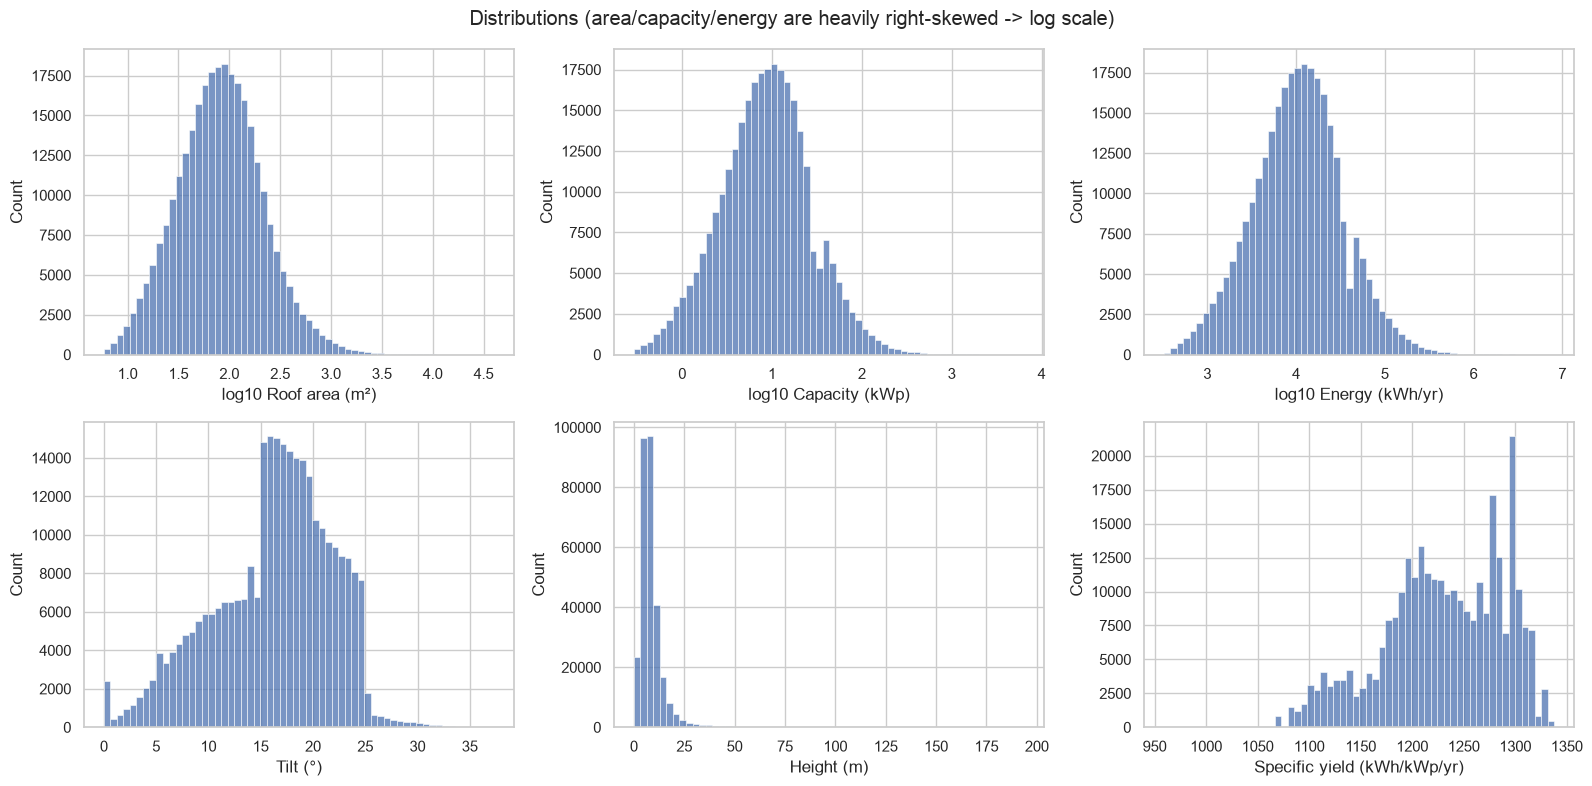

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (c, t) in zip(ax.ravel(), [("roof_area_m2","Roof area (m²)"),("capacity_kwp","Capacity (kWp)"),
        ("energy_kwh_yr","Energy (kWh/yr)"),("tilt_deg","Tilt (°)"),
        ("height_m","Height (m)"),("specific_yield_kwh_kwp","Specific yield (kWh/kWp/yr)")]):
    s = df[c]
    if c in ("roof_area_m2","capacity_kwp","energy_kwh_yr"):
        sns.histplot(np.log10(s), bins=60, ax=a); a.set_xlabel(f"log10 {t}")
    else:
        sns.histplot(s, bins=60, ax=a); a.set_xlabel(t)
plt.suptitle("Distributions (area/capacity/energy are heavily right-skewed -> log scale)"); plt.tight_layout()

### 5.2 By building type

In [12]:
g = df.groupby("building_type", observed=True).agg(
    buildings=("uuid","count"), capacity_mwp=("capacity_kwp", lambda s: s.sum()/1e3),
    energy_gwh=("energy_kwh_yr", lambda s: s.sum()/1e6), median_kwp=("capacity_kwp","median"),
    mean_kwp=("capacity_kwp","mean"), median_yield=("specific_yield_kwh_kwp","median"),
    median_height=("height_m","median")).sort_values("energy_gwh", ascending=False)
g["share_energy_%"] = g.energy_gwh / g.energy_gwh.sum() * 100
g["share_buildings_%"] = g.buildings / g.buildings.sum() * 100
g

,buildings,capacity_mwp,energy_gwh,median_kwp,mean_kwp,median_yield,median_height,share_energy_%,share_buildings_%
building_type,,,,,,,,,
multi-family residential,163543,"2,350.96","2,872.07",9.19,14.38,"1,225.22",7.34,44.79,55.25
single family residential,81235,804.68,982.47,5.56,9.91,"1,225.33",6.35,15.32,27.45
industrial,23623,754.66,981.83,11.46,31.95,"1,297.00",7.83,15.31,7.98
commercial,16569,707.55,879.24,17.84,42.70,"1,231.30",9.73,13.71,5.60
public,11014,567.82,696.44,20.31,51.55,"1,226.00",9.56,10.86,3.72


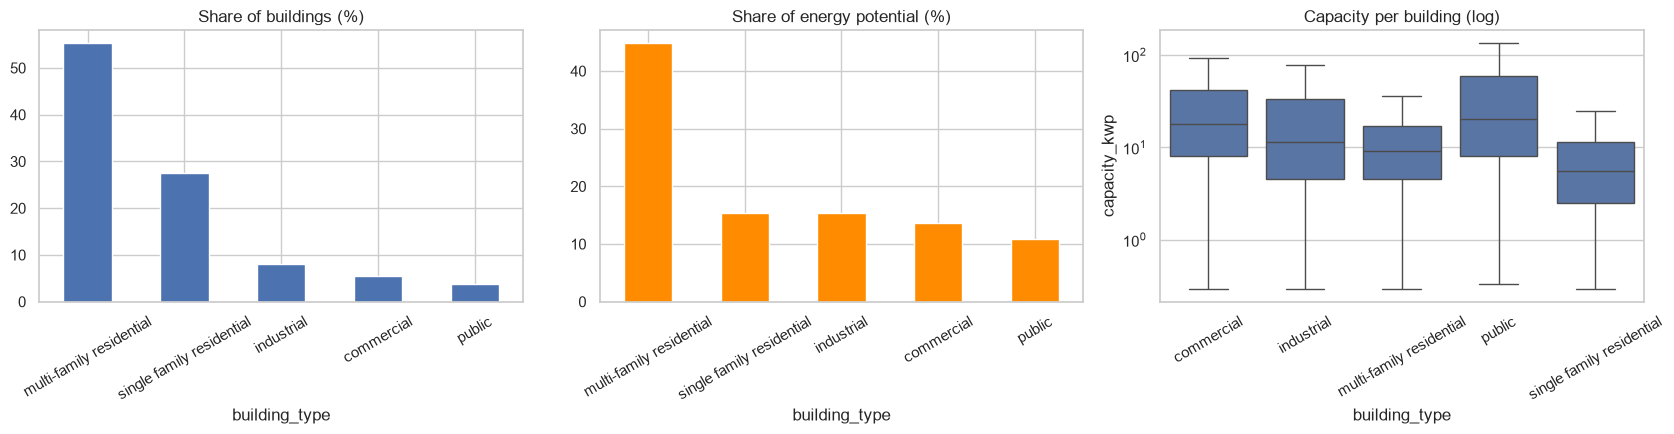

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
g["share_buildings_%"].plot.bar(ax=ax[0], title="Share of buildings (%)")
g["share_energy_%"].plot.bar(ax=ax[1], color="darkorange", title="Share of energy potential (%)")
sns.boxplot(data=df, x="building_type", y="capacity_kwp", showfliers=False, ax=ax[2]); ax[2].set_yscale("log")
ax[2].set_title("Capacity per building (log)"); [a.tick_params(axis="x", rotation=30) for a in ax]
plt.tight_layout()

### 5.3 Relationships

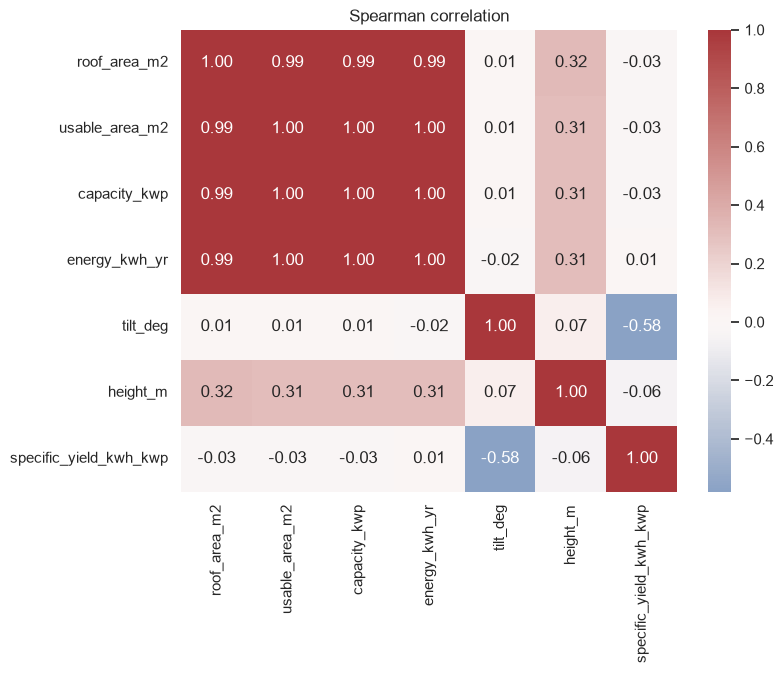

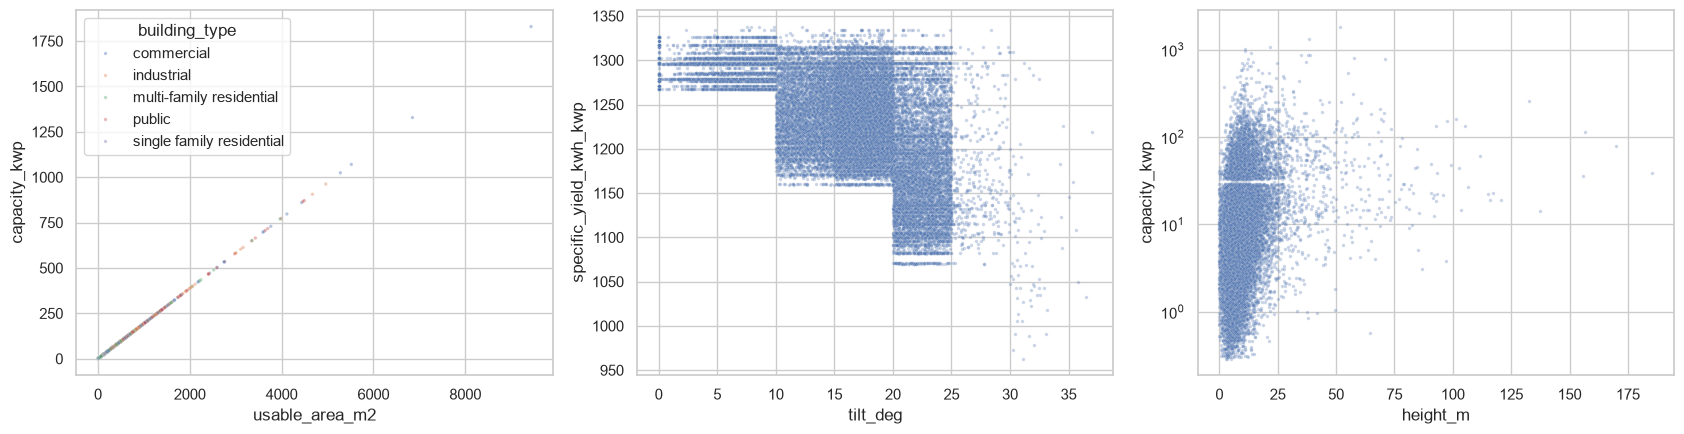

In [14]:
cols = ["roof_area_m2","usable_area_m2","capacity_kwp","energy_kwh_yr","tilt_deg","height_m","specific_yield_kwh_kwp"]
plt.figure(figsize=(8,6)); sns.heatmap(df[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Spearman correlation"); plt.show()

s = df.sample(30000, random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=s, x="usable_area_m2", y="capacity_kwp", hue="building_type", s=6, alpha=.4, ax=ax[0])
sns.scatterplot(data=s, x="tilt_deg", y="specific_yield_kwh_kwp", s=6, alpha=.3, ax=ax[1])
sns.scatterplot(data=s, x="height_m", y="capacity_kwp", s=6, alpha=.3, ax=ax[2]); ax[2].set_yscale("log")
plt.tight_layout()

### 5.4 Roof size classes

In [15]:
sc = df.groupby("size_class", observed=True).agg(buildings=("uuid","count"), mwp=("capacity_kwp", lambda s: s.sum()/1e3),
        gwh=("energy_kwh_yr", lambda s: s.sum()/1e6))
sc["share_mwp_%"] = sc.mwp/sc.mwp.sum()*100; sc["share_buildings_%"] = sc.buildings/sc.buildings.sum()*100
sc

,buildings,mwp,gwh,share_mwp_%,share_buildings_%
size_class,,,,,
<5 kWp,94135,251.43,309.46,4.85,31.80
5-10,70129,510.43,626.46,9.84,23.69
10-50,112568,"2,306.52","2,829.53",44.48,38.03
50-100,13272,902.39,"1,117.67",17.40,4.48
>100 kWp,5880,"1,214.90","1,528.93",23.43,1.99


## 6. Performance metrics
Four groups: **(A)** technical performance, **(B)** concentration / targeting, **(C)** national, fossil and Meralco context, **(D)** adoption scenarios.

### A. Technical performance

In [16]:
tot_kwp = df.capacity_kwp.sum(); tot_kwh = df.energy_kwh_yr.sum() * PERFORMANCE_RATIO_HAIRCUT
tech = pd.Series({
    "Buildings analysed": len(df),
    "Usable roof area (km²)": df.usable_area_m2.sum()/1e6,
    "Installable capacity (GWp)": tot_kwp/1e6,
    "Annual energy (TWh)": tot_kwh/1e9,
    "Fleet specific yield (kWh/kWp/yr)": tot_kwh/tot_kwp,
    "Fleet capacity factor (%)": tot_kwh/tot_kwp/8760*100,
    "Capacity density (kWp/m² usable)": tot_kwp/df.usable_area_m2.sum(),
    "Usable / roof area (%)": df.usable_area_m2.sum()/df.roof_area_m2.sum()*100,
    "Median system size (kWp)": df.capacity_kwp.median(),
    "Energy per building, median (MWh/yr)": df.energy_mwh_yr.median(),
})
tech.to_frame("value")

,value
Buildings analysed,"295,984.00"
Usable roof area (km²),26.73
Installable capacity (GWp),5.19
Annual energy (TWh),6.41
Fleet specific yield (kWh/kWp/yr),"1,236.49"
Fleet capacity factor (%),14.12
Capacity density (kWp/m² usable),0.19
Usable / roof area (%),64.64
Median system size (kWp),8.58
"Energy per building, median (MWh/yr)",10.52


### B. Concentration: where is the potential?

Top  1% of roofs hold 17.1% of energy potential
Top  5% of roofs hold 36.8% of energy potential
Top 10% of roofs hold 50.0% of energy potential
Top 20% of roofs hold 65.2% of energy potential
Top 50% of roofs hold 88.3% of energy potential


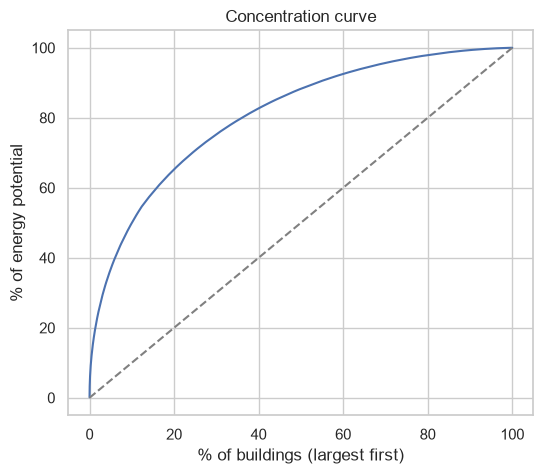

25% of potential reachable with 6,492 roofs (2.2% of buildings)
50% of potential reachable with 29,666 roofs (10.0% of buildings)
75% of potential reachable with 87,848 roofs (29.7% of buildings)


In [17]:
d = df.sort_values("capacity_kwp", ascending=False).reset_index(drop=True)
d["cum_buildings_%"] = (d.index+1)/len(d)*100
d["cum_energy_%"] = d.energy_kwh_yr.cumsum()/d.energy_kwh_yr.sum()*100
for p in (1, 5, 10, 20, 50):
    print(f"Top {p:>2}% of roofs hold {d.loc[int(len(d)*p/100)-1,'cum_energy_%']:.1f}% of energy potential")
plt.figure(figsize=(6,5)); plt.plot(d["cum_buildings_%"], d["cum_energy_%"]); plt.plot([0,100],[0,100],"--",c="grey")
plt.xlabel("% of buildings (largest first)"); plt.ylabel("% of energy potential"); plt.title("Concentration curve"); plt.show()
# roofs needed for X GWh
for target in (0.25, 0.5, 0.75):
    k = (d["cum_energy_%"] >= target*100).idxmax()+1
    print(f"{target:.0%} of potential reachable with {k:,} roofs ({k/len(d):.1%} of buildings)")

### C. National, fossil-fuel and Meralco context

In [18]:
twh = tot_kwh/1e9
ctx = pd.Series({
    "Solar potential (TWh/yr)": twh,
    "% of national generation": twh/NATIONAL_GEN_TWH*100,
    "% of Meralco annual sales": twh/MERALCO_SALES_TWH*100,
    "% of coal generation displaceable": twh/(NATIONAL_GEN_TWH*COAL_SHARE)*100,
    "Oil-fired power displaceable (TWh) - upper bound": min(twh, NATIONAL_GEN_TWH*OIL_SHARE_POWER),
    "CO2 avoided (Mt/yr) at full potential": tot_kwh*GRID_EF_KG_KWH/1e9,
    "Bill value of self-consumed energy (PHP bn/yr)": tot_kwh*SELF_CONSUMPTION*TARIFF_PHP_KWH/1e9,
})
ctx.to_frame("value")

,value
Solar potential (TWh/yr),6.41
% of national generation,5.34
% of Meralco annual sales,12.82
% of coal generation displaceable,8.62
Oil-fired power displaceable (TWh) - upper bound,1.20
CO2 avoided (Mt/yr) at full potential,4.49
Bill value of self-consumed energy (PHP bn/yr),61.56


**Reading this table honestly**
- Oil is ~1% of power, so grid-connected solar cannot much reduce Middle East crude dependence. The row above shows that cap. The oil link only exists through electrified transport or diesel-genset displacement, which this dataset cannot measure.
- Coal displacement and Meralco-share figures are technical potential, not forecasts.

### D. Adoption scenarios

In [19]:
rows = []
for a in ADOPTION_SCENARIOS:
    e = tot_kwh*a/1e9
    rows.append({"adoption": f"{a:.0%}", "capacity_GWp": tot_kwp*a/1e6, "energy_TWh": e,
                 "% national gen": e/NATIONAL_GEN_TWH*100, "% Meralco sales": e/MERALCO_SALES_TWH*100,
                 "% coal gen displaced": e/(NATIONAL_GEN_TWH*COAL_SHARE)*100,
                 "CO2_avoided_Mt": e*1e9*GRID_EF_KG_KWH/1e9,
                 "avoided_grid_purchase_PHP_bn": e*1e9*SELF_CONSUMPTION*TARIFF_PHP_KWH/1e9})
scen = pd.DataFrame(rows).set_index("adoption"); scen

,capacity_GWp,energy_TWh,% national gen,% Meralco sales,% coal gen displaced,CO2_avoided_Mt,avoided_grid_purchase_PHP_bn
adoption,,,,,,,
5%,0.26,0.32,0.27,0.64,0.43,0.22,3.08
10%,0.52,0.64,0.53,1.28,0.86,0.45,6.16
25%,1.30,1.60,1.34,3.21,2.15,1.12,15.39
50%,2.59,3.21,2.67,6.41,4.31,2.24,30.78


In [20]:
# By sector, large (commercial/industrial/public) first: best daytime match, fewer decision-makers
sector = df.groupby("building_type", observed=True).agg(buildings=("uuid","count"),
          gwh=("energy_kwh_yr", lambda s: s.sum()/1e6), median_kwp=("capacity_kwp","median"))
sector["GWh per 1000 buildings"] = sector.gwh / sector.buildings * 1000
sector.sort_values("GWh per 1000 buildings", ascending=False)

,buildings,gwh,median_kwp,GWh per 1000 buildings
building_type,,,,
public,11014,696.44,20.31,63.23
commercial,16569,879.24,17.84,53.07
industrial,23623,981.83,11.46,41.56
multi-family residential,163543,"2,872.07",9.19,17.56
single family residential,81235,982.47,5.56,12.09


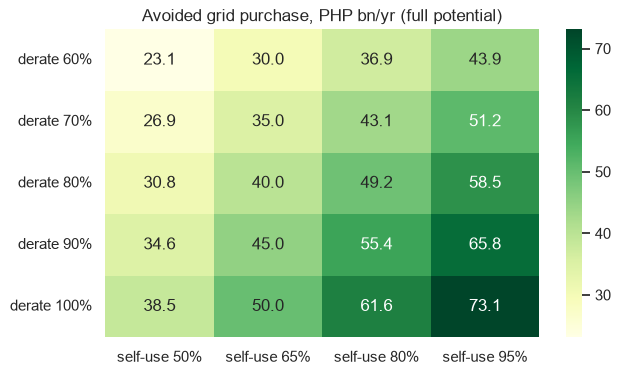

In [21]:
# Sensitivity: derating (soiling/shading/inverter) x self-consumption -> avoided purchase (PHP bn/yr), 100% potential
derate = [0.6, 0.7, 0.8, 0.9, 1.0]; selfc = [0.5, 0.65, 0.8, 0.95]
sens = pd.DataFrame([[df.energy_kwh_yr.sum()*d_*s_*TARIFF_PHP_KWH/1e9 for s_ in selfc] for d_ in derate],
                    index=[f"derate {d_:.0%}" for d_ in derate], columns=[f"self-use {s_:.0%}" for s_ in selfc])
plt.figure(figsize=(7,4)); sns.heatmap(sens, annot=True, fmt=".1f", cmap="YlGn"); plt.title("Avoided grid purchase, PHP bn/yr (full potential)"); plt.show()

## 7. Findings & limitations

**Fill in after running** with the numbers above. Questions to answer:
1. Does the potential (section C) meaningfully offset coal and Meralco supply, or is it marginal?
2. Which building types and size classes concentrate the potential (sections 5.2, 5.4, B)?
3. How far do results move under derating and self-consumption assumptions (section D)?

**Limitations**
- Technical potential only; no shading, structural, ownership or grid-hosting constraints.
- No installation prices in the data (`Unit_installation_price` is empty), so no payback, LCOE or NPV yet.
- No demand data: self-consumption is an assumption. Solar without storage covers daytime load only.
- "Manila" may cover more than the city proper; summed roof area is close to the whole city's land area, so check coverage.
- Context constants in section 1 are unverified placeholders.
- Middle East dependence is mostly a transport/industrial-oil problem, which rooftop solar addresses only indirectly.